# Practice B5 · Copy number on one coordinate axis

**Read depth → normalise → log2 ratio → segments → check against the truth → tracks on one axis → genome-wide view**

*Genomic Data Processing · Day 5 (10/27) · Data visualization in genetics and genomics · about 20 minutes*

> **All data in this practice are simulated (computer-generated). No real patient data are used.**
> The read depths are simulated, but every annotation is real hg38 data – the chromosome length, MANE Select genes,
> UCSC segmental duplications and the ClinGen 22q11.2 region – so every coordinate can be checked in a genome browser.

**How to use this notebook.** Run the cells from top to bottom (Shift + Enter). The steps follow the four beats of
Practice B: **Question → Test → Check → Visualize**. Cells that start with `# CHECK ·` compare your numbers with a
reference value and print ✓ (fine) or ✗ (look again before you go on). Each step ends with **What changed?** and a
**Your turn** task; try it first, then click *Answer* to unfold the answer.

| File | What is inside |
|---|---|
| `data/cnv_chr22_10kb.tsv` | one row per 10-kb bin of chr22 (hg38; `start` 0-based, `end` exclusive): GC fraction, `mappable`, patient and reference depth (x) |
| `data/cnv_genes_chr22.tsv` | MANE Select protein-coding genes on chr22, 17–23 Mb (real) |
| `data/cnv_segdups_chr22.tsv` | UCSC segmental duplications, chr22 18.0–22.4 Mb (real), with the LCR22 block (A–D) |
| `data/cnv_genome_1mb.tsv` | 1-Mb bins of chr1–22: log2 ratios of the same patient and of a colorectal tumour |
| `data/truth/cnv_truth.tsv` | the planted events – open it only in the CHECK step of B5.3 |

| Step | Beat | Topic | min |
|---|---|---|---|
| B5.1 | Question | why the depth halves | 3 |
| B5.2 | Test | depth → log2 ratio, masks, GC | 5 |
| B5.3 | Test + Check | segments; breakpoints vs truth | 5 |
| B5.4 | Visualize | tracks on one x-axis | 4 |
| B5.5 | Visualize + Check | genome-wide view at 1 Mb | 3 |

In [1]:
# Step 0 · Set-up: imports, folders and figure style
import os, sys, time
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "dviz.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
os.environ.setdefault("NUMBA_CACHE_DIR", str(ROOT / ".numba_cache"))   # needed by umap-learn on some systems
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import dviz
dviz.use_style()
DATA, FIG = ROOT / "data", ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
T_START = time.time()
pd.set_option("display.width", 130)

## Step B5.1 · Question: why does the read depth halve?  *(3 min)*

### Question

*Does this patient carry the 22q11.2 deletion, where exactly is it, and how strong is the evidence?*

**Why this step.** The 22q11.2 deletion syndrome (also called DiGeorge or velocardiofacial syndrome) is the most
common microdeletion in humans – roughly 1 in 4,000 births. Most patients miss the same piece of one copy of
chromosome 22, about 2.5 Mb long with about 40 protein-coding genes. Losing one copy of *TBX1* explains much of the
heart and palate phenotype. The deletion is so common because it is flanked by **low-copy repeats** (LCR22A–D): long,
nearly identical copies of DNA that can pair up by mistake during meiosis and cut out everything between them.

The patient's DNA is **constitutional** (the same in every cell), so the deleted region has exactly **one copy instead
of two**. One copy gives half as many DNA fragments, so half as many reads: the depth falls from about 30x to about 15x.

**New terms**
* **Read depth (x)** – how many reads cover each base on average; 30x = every base is read about 30 times.
* **Bin** – a fixed window of the genome (here 10 kb = 10,000 bases); we summarise the depth per bin.
* **Constitutional** – present from conception in every cell; a tumour sample is a mixture of tumour and normal cells.
* **Reference panel** – the median depth of 10 people without the deletion, sequenced the same way.
* **Segmental duplication** – a stretch of DNA (> 1 kb) present in two or more nearly identical copies; LCR22A–D are segmental duplications.
* **Mappable** – a bin in which reads can be placed uniquely. Reads from near-identical copies cannot, so those bins are masked.

In [2]:
# Step B5.1 · load the 10-kb bins (BED style: start is 0-based, end is exclusive)
cn = pd.read_csv(DATA / "cnv_chr22_10kb.tsv", sep="\t")
cn["mappable"] = cn["mappable"].astype(str).eq("True")          # the file stores True/False as text
print(f"{len(cn):,} bins on {cn['chrom'].iloc[0]} (hg38), from 0 to {cn['end'].max():,} bp")
print(f"mappable bins: {cn['mappable'].sum():,} ({cn['mappable'].mean():.0%}); the others are masked")
cn.iloc[1890:1898]          # 18.90-18.98 Mb: the end of LCR22A (masked), then unique sequence

5,082 bins on chr22 (hg38), from 0 to 50,818,468 bp
mappable bins: 3,410 (67%); the others are masked


,chrom,start,end,gc,mappable,depth_patient,depth_reference
1890,chr22,18900000,18910000,0.4238,False,5.670,6.211
1891,chr22,18910000,18920000,0.4332,False,3.180,6.096
1892,chr22,18920000,18930000,0.4484,False,7.815,13.557
1893,chr22,18930000,18940000,0.4737,False,10.410,12.147
1894,chr22,18940000,18950000,0.4698,True,12.585,29.728
1895,chr22,18950000,18960000,0.4862,True,16.560,27.694
1896,chr22,18960000,18970000,0.4949,True,14.385,26.960
1897,chr22,18970000,18980000,0.4542,True,15.075,27.644


In [3]:
# Step B5.1 · worked example: one bin inside TBX1 (in 22q11.2) and one inside MAPK1 (outside)
for gene, bin_start in [("TBX1", 19_760_000), ("MAPK1", 21_800_000)]:
    row = cn.loc[cn["start"] == bin_start].iloc[0]
    print(f"{gene:6s} chr22:{row['start'] + 1:,}-{row['end']:,} (1-based)   patient {row['depth_patient']:5.1f}x   "
          f"reference {row['depth_reference']:5.1f}x   patient / reference = "
          f"{row['depth_patient'] / row['depth_reference']:.2f}")

TBX1   chr22:19,760,001-19,770,000 (1-based)   patient  16.1x   reference  27.8x   patient / reference = 0.58
MAPK1  chr22:21,800,001-21,810,000 (1-based)   patient  29.2x   reference  27.2x   patient / reference = 1.07


In [4]:
# CHECK · the file covers the whole of chr22 (hg38 length 50,818,468 bp) in 10-kb bins
dviz.check("B5.n_bins", len(cn), 5082)
dviz.check("B5.chr22_end", int(cn["end"].max()), 50_818_468)
dviz.check("B5.n_mappable", int(cn["mappable"].sum()), between=(3000, 4000))
dviz.check("B5.first_mappable_Mb", cn.loc[cn["mappable"], "start"].min() / 1e6, between=(15.0, 16.0))

CHECK ✓ B5.n_bins = 5,082   (reference: 5082)
CHECK ✓ B5.chr22_end = 50,818,468   (reference: 50818468)
CHECK ✓ B5.n_mappable = 3,410   (reference: in [3000, 4000])
CHECK ✓ B5.first_mappable_Mb = 15.41   (reference: in [15.0, 16.0])


True

**What changed?** Nothing is computed yet – we looked at the data. chr22 has 5,082 bins of 10 kb;
3,410 are mappable. The first 15.4 Mb (short arm, centromere and
repeats) contain no unique sequence. In the *TBX1* bin the patient has about half the reference depth; in the *MAPK1*
bin about the same. The ratios are not exactly 0.5 and 1.0 because the patient was sequenced a little deeper than
the panel – Step B5.2 fixes that.

**Your turn.** Look at the eight rows printed above (18.90–18.98 Mb). Why do the masked rows (`mappable = False`)
jump around, while the first mappable rows show the patient at about half the reference?

<details><summary>Answer</summary>

These bins lie at the end of LCR22A, a near-identical repeat. A read from there fits LCR22A, B, C or D equally
well, so the aligner gives it a low mapping quality and most such reads are filtered out: the depth is low and erratic
in **every** sample, and it also depends on how many LCR22 copies each person carries. From 18.94 Mb on the sequence is
unique, and the patient has about half the reference depth there: we are inside the deletion.
</details>

## Step B5.2 · Test: from read depth to a log2 ratio  *(5 min)*

### Test

**Why this step.** Raw depth changes for reasons that have nothing to do with copy number: (1) one sample was simply
sequenced more than another, and (2) some bins collect fewer reads in *every* sample – for example GC-rich bins, which
amplify less well, or repeats. We remove (1) by dividing each sample by its **median depth over mappable bins**, and
(2) by dividing the patient by the **reference panel**, which has the same local biases. **log2** makes gains and
losses symmetric around 0.

**New terms**
* **Median normalisation** – divide every bin by the sample's median bin, so that a typical bin becomes 1.
* **Ratio** – patient ÷ reference (both normalised): 2 copies → 1, 1 copy → 0.5, 3 copies → 1.5.
* **log2 ratio** – log2 of the ratio: 2 copies → 0, 1 copy → −1, 3 copies → +0.58, 0 copies → −∞.
* **GC fraction** – the share of G and C bases in a bin (0–1).
* **Mask** – set a bin to "missing" (`NaN`) so that no later step uses it.

In [5]:
# Step B5.2 · normalise by the median, divide by the reference, take log2, mask unreliable bins
ok = cn["mappable"]
pat_median = cn.loc[ok, "depth_patient"].median()          # typical bin of the patient (x)
ref_median = cn.loc[ok, "depth_reference"].median()        # typical bin of the reference panel (x)
cn["ratio"] = ((cn["depth_patient"] / pat_median) / (cn["depth_reference"] / ref_median)).where(ok)
cn["log2"] = np.log2(cn["ratio"])                          # NaN where the bin is masked
print(f"median depth over mappable bins: patient {pat_median:.1f}x, reference {ref_median:.1f}x")
print(f"log2 ratios: {cn['log2'].notna().sum():,} bins; {cn['log2'].isna().sum():,} masked (NaN)")
cn.loc[cn["start"].isin([19_760_000, 21_800_000]), ["start", "depth_patient", "depth_reference", "ratio", "log2"]].round(3)

median depth over mappable bins: patient 28.5x, reference 27.2x
log2 ratios: 3,410 bins; 1,672 masked (NaN)


,start,depth_patient,depth_reference,ratio,log2
1976,19760000,16.080,27.819,0.553,-0.856
2180,21800000,29.205,27.206,1.026,0.037


In [6]:
# CHECK · copy-neutral bins sit near 0, the ClinGen 22q11.2 core near -1, and the GC bias cancels
away = ok & ((cn["end"] <= 18_000_000) | (cn["start"] >= 22_000_000))   # far from 22q11.2
core = ok & (cn["start"] >= 18_924_717) & (cn["end"] <= 21_111_383)     # ClinGen ISCA-37446 (hg38)
dviz.check("B5.median_log2_outside", cn.loc[away, "log2"].median(), between=(-0.1, 0.1))
dviz.check("B5.median_log2_core", cn.loc[core, "log2"].median(), between=(-1.1, -0.9))
dviz.check("B5.sd_log2", cn.loc[away, "log2"].std(), between=(0.15, 0.25))
gc_group = pd.qcut(cn.loc[away, "gc"], 10, labels=False)                 # 10 groups of bins with similar GC
raw_by_gc = cn.loc[away, "depth_patient"].groupby(gc_group).median()
ratio_by_gc = cn.loc[away, "ratio"].groupby(gc_group).median()
dviz.check("B5.gc_effect_raw", (raw_by_gc.max() - raw_by_gc.min()) / pat_median, between=(0.1, 0.5),
           note="range of the 10 GC-group medians, raw depth")
dviz.check("B5.gc_effect_ratio", ratio_by_gc.max() - ratio_by_gc.min(), between=(0.0, 0.08),
           note="the same after dividing by the reference")

CHECK ✓ B5.median_log2_outside = 0.04948   (reference: in [-0.1, 0.1])
CHECK ✓ B5.median_log2_core = -0.9615   (reference: in [-1.1, -0.9])
CHECK ✓ B5.sd_log2 = 0.2187   (reference: in [0.15, 0.25])
CHECK ✓ B5.gc_effect_raw = 0.2628   (reference: in [0.1, 0.5])  range of the 10 GC-group medians, raw depth
CHECK ✓ B5.gc_effect_ratio = 0.03945   (reference: in [0.0, 0.08])  the same after dividing by the reference


True

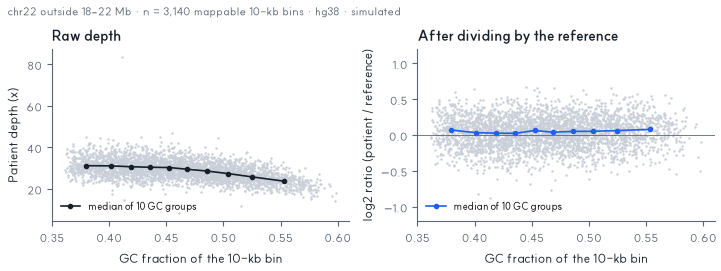

In [7]:
# Step B5.2 · picture of the GC effect: raw depth depends on GC, the log2 ratio does not
gc_mid = cn.loc[away, "gc"].groupby(gc_group).median()
fig, axs = plt.subplots(1, 2, figsize=(7.2, 2.7), layout="constrained")
axs[0].scatter(cn.loc[away, "gc"], cn.loc[away, "depth_patient"], s=3, color=dviz.GREY, lw=0)
axs[0].plot(gc_mid, raw_by_gc, color=dviz.INK, marker="o", ms=3, lw=1.2, label="median of 10 GC groups")
axs[0].set(xlabel="GC fraction of the 10-kb bin", ylabel="Patient depth (x)", title="Raw depth")
axs[1].scatter(cn.loc[away, "gc"], cn.loc[away, "log2"], s=3, color=dviz.GREY, lw=0)
axs[1].plot(gc_mid, np.log2(ratio_by_gc), color=dviz.BLUE, marker="o", ms=3, lw=1.2, label="median of 10 GC groups")
axs[1].axhline(0, color=dviz.SLATE, lw=0.6)
axs[1].set(xlabel="GC fraction of the 10-kb bin", ylabel="log2 ratio (patient / reference)",
           title="After dividing by the reference", ylim=(-1.2, 1.2))
for ax in axs:
    ax.legend(loc="lower left", fontsize=7)
fig.suptitle(f"chr22 outside 18–22 Mb · n = {int(away.sum()):,} mappable 10-kb bins · hg38 · simulated",
             fontsize=8, x=0.01, ha="left", color=dviz.SLATE)
dviz.savefig(fig, "B5_gc_effect")
plt.show()

**What changed?** Depth in x → a **log2 ratio** per bin, with 3,410 usable bins and all masked
bins set to `NaN`. Far from 22q11.2 the median log2 ratio is +0.049 and inside the
ClinGen core −0.962; one bin scatters with SD 0.22. The GC effect
(spread of the 10 GC-group medians) shrank from 26% of the depth to
4% after dividing by the reference.

*Why is the normal level not exactly 0?* Dividing by the patient's median assumes that most bins have two copies.
On chr22 alone, 6% of the patient's mappable bins are deleted; that lowers the
patient's median a little, so every normal bin looks about 4% higher. In a whole genome the effect disappears; real tools re-centre on the
copy-neutral peak.

**Your turn.** Before you look: what log2 ratio do you expect for a bin with **three** copies, and for a bin with
**no** copy? What happens to the patient's depth in a bin with no copy?

<details><summary>Answer</summary>

Three copies: ratio 3/2 = 1.5, log2(1.5) ≈ **+0.58** (not +1; +1 would be four copies). No copy: no reads, ratio
0, log2(0) = **−∞** – plots usually clip it at −3. Gains are always smaller in log2 than losses of the same size,
which is why we draw the expected values as reference lines.
</details>

## Step B5.3 · Test and Check: segment, then compare with the truth  *(5 min)*

### Test

**Why this step.** One bin is noisy, so one low bin means nothing. A real deletion moves **many neighbouring bins
together**. **Segmentation** finds the places where the average level changes and reports stretches of constant mean
("segments"). `dviz.segment` is a short, readable version of circular binary segmentation (CBS): split the data where
the means on the two sides differ most, keep the split only if the difference is large compared with the noise
(`z = 6`), and repeat inside each piece. Masked bins are skipped.

**New terms**
* **Segment** – a run of adjacent bins with the same mean log2 ratio (one copy-number state).
* **Breakpoint** – the position where a deletion starts or ends.
* **Copy number from log2** – copies = 2 × 2^(mean log2): −1 → 1 copy, 0 → 2 copies.
* **NAHR** (non-allelic homologous recombination) – two similar repeats (here LCR22A and LCR22D) pair up by mistake and
  the DNA between them is lost; the breakpoints therefore lie *inside* the repeats.

In [8]:
# Step B5.3 · segment the log2 ratios (masked bins are skipped) and turn bin numbers into coordinates
seg = dviz.segment(cn["log2"], min_size=5, z=6)
seg["start"] = cn["start"].to_numpy()[seg["first"]]        # start of the first bin (0-based)
seg["end"] = cn["end"].to_numpy()[seg["last"]]             # end of the last bin (exclusive)
seg["length_Mb"] = (seg["end"] - seg["start"]) / 1e6
seg["copy_number"] = 2 * 2 ** seg["mean"]                  # log2 ratio -> number of copies
seg.round(3)

,first,last,n_bins,mean,start,end,length_Mb,copy_number
0,1541,1815,275,0.049,15410000,18160000,2.75,2.068
1,1894,2110,208,-0.965,18940000,21110000,2.17,1.025
2,2144,5080,2927,0.039,21440000,50810000,29.37,2.055


In [9]:
# Step B5.3 · the deletion = the segment with clearly fewer than 2 copies; which genes does it contain?
dele = seg.loc[seg["copy_number"] < 1.5].iloc[0]
d_start, d_end = int(dele["start"]), int(dele["end"])      # a row of mixed numbers is float: make integers
in_del = ok & (cn["start"] >= d_start) & (cn["end"] <= d_end)
median_inside = cn.loc[in_del, "log2"].median()
print(f"deletion, BED (0-based start):   chr22  {d_start}  {d_end}")
print(f"deletion, 1-based (as a browser): chr22:{d_start + 1:,}-{d_end:,}  ({(d_end - d_start) / 1e6:.2f} Mb, hg38)")
print(f"{int(dele['n_bins'])} mappable bins · mean log2 {dele['mean']:.3f} · median {median_inside:.3f} · "
      f"copy number {dele['copy_number']:.2f}")
genes = pd.read_csv(DATA / "cnv_genes_chr22.tsv", sep="\t")
inside = genes.loc[(genes["start"] < d_end) & (genes["end"] > d_start)]
print(f"{len(inside)} protein-coding genes (MANE Select) overlap the deletion:")
print(", ".join(inside["gene"]))

deletion, BED (0-based start):   chr22  18940000  21110000
deletion, 1-based (as a browser): chr22:18,940,001-21,110,000  (2.17 Mb, hg38)
208 mappable bins · mean log2 -0.965 · median -0.962 · copy number 1.02
42 protein-coding genes (MANE Select) overlap the deletion:
DGCR2, ESS2, TSSK2, GSC2, SLC25A1, CLTCL1, HIRA, MRPL40, C22orf39, UFD1, CDC45, CLDN5, SEPTIN5, GP1BB, TBX1, GNB1L, RTL10, TXNRD2, COMT, ARVCF, TANGO2, DGCR8, TRMT2A, RANBP1, ZDHHC8, CCDC188, RTN4R, DGCR6L, ZNF74, SCARF2, KLHL22, MED15, PI4KA, SERPIND1, SNAP29, CRKL, AIFM3, LZTR1, THAP7, P2RX6, SLC7A4, LRRC74B


### Check

**Open the truth file only now.** It says where the deletion was planted. Because both breakpoints lie inside LCR22A
and LCR22D, where every bin is masked, read depth can only say that each breakpoint lies *somewhere* between the last
normal bin and the first deleted bin. So we check three things: the called ends fall in the right repeats
(LCR22A, LCR22D; ± 50 kb), the true breakpoints lie inside those uncertainty intervals, and the level is one copy.

In [10]:
# CHECK · breakpoints vs the planted truth and the LCR22 repeats; level = one copy
truth = pd.read_csv(DATA / "truth" / "cnv_truth.tsv", sep="\t")
t = truth.loc[truth["sample"] == "patient"].iloc[0]
sd = pd.read_csv(DATA / "cnv_segdups_chr22.tsv", sep="\t")
lcr = sd.loc[sd["lcr22"].notna()].groupby("lcr22").agg(start=("start", "min"), end=("end", "max"))
i = int(seg.index[seg["start"] == d_start][0])
left, right = int(seg.loc[i - 1, "end"]), int(seg.loc[i + 1, "start"])     # the nearest normal bins
print(f"truth: chr22:{t['start'] + 1:,}-{t['end']:,} ({(t['end'] - t['start']) / 1e6:.2f} Mb); "
      f"read depth: start in ({left:,}, {d_start:,}], end in [{d_end:,}, {right:,})")
A, D = lcr.loc["A"], lcr.loc["D"]
dviz.check("B5.start_in_LCR22A", bool(A["start"] - 50_000 <= d_start <= A["end"] + 50_000), True)
dviz.check("B5.end_in_LCR22D", bool(D["start"] - 50_000 <= d_end <= D["end"] + 50_000), True)
dviz.check("B5.truth_in_intervals", bool(left <= t["start"] <= d_start and d_end <= t["end"] <= right), True)
dviz.check("B5.mean_log2_del", float(dele["mean"]), between=(-1.1, -0.9))
dviz.check("B5.copy_number", float(dele["copy_number"]), 1.0, tol=0.1)
dviz.check("B5.n_segments", len(seg), 3)
edge = genes.loc[(genes["start"] < t["end"]) & (genes["end"] > t["start"]) & ~genes["gene"].isin(inside["gene"])]
print("genes in the planted deletion but outside the call (in the masked repeats):", ", ".join(edge["gene"]))

truth: chr22:18,717,065-21,342,616 (2.63 Mb); read depth: start in (18,160,000, 18,940,000], end in [21,110,000, 21,440,000)
CHECK ✓ B5.start_in_LCR22A = True   (reference: True)
CHECK ✓ B5.end_in_LCR22D = True   (reference: True)
CHECK ✓ B5.truth_in_intervals = True   (reference: True)
CHECK ✓ B5.mean_log2_del = -0.9647   (reference: in [-1.1, -0.9])
CHECK ✓ B5.copy_number = 1.025   (reference: 1.0 ± 0.1)
CHECK ✓ B5.n_segments = 3   (reference: 3)
genes in the planted deletion but outside the call (in the masked repeats): DGCR6, PRODH


**What changed?** 3,410 noisy log2 values → 3 segments. The deletion is
called at chr22:18,940,001–21,110,000 (hg38, 1-based; 2.17 Mb,
208 mappable bins), mean log2 −0.965, copy number
1.02, and it contains 42 protein-coding genes. The planted
deletion is longer (2.63 Mb): its breakpoints lie inside LCR22A and LCR22D, and read depth
can only place them within intervals of 780 kb and 330 kb.

**Your turn.** The deletion's mean log2 ratio is −0.965 from 208 bins, and
one bin has SD 0.22. Estimate the standard error of the mean (SD ÷ √n). Is the mean consistent
with exactly one copy?

<details><summary>Answer</summary>

SE ≈ 0.22 ÷ √208 ≈ 0.015. The mean is close to −1 but
a little higher, because the normal segments sit at about +0.05 (Step B5.2): relative
to its neighbours the deletion is at about −1.01, i.e. exactly one copy lost. With
208 bins, even a small offset in the baseline is visible – always compare a segment with the copy-neutral level.
</details>

## Step B5.4 · Visualize: tracks on one shared x-axis  *(4 min)*

### Visualize

**Why this step.** Depth, log2 ratio, genes and repeats are different kinds of evidence, but they share one
coordinate: the position on chr22. Drawing them as **tracks** on one shared x-axis lines the evidence up vertically:
the depth halves exactly where the log2 ratio drops, the genes in the shaded region lose one copy, and both ends of the
call touch the grey LCR22 blocks. A genome browser (IGV, UCSC) does the same.

**New terms**
* **Track** – one horizontal panel of evidence plotted against genome position.
* **`sharex=True`** – all panels use the same x-axis; zooming one panel zooms all.

In [11]:
# Step B5.4 · helpers: gene boxes with italic labels for key genes, and segmental-duplication boxes
KEY_GENES = ["USP18", "PRODH", "HIRA", "TBX1", "COMT", "DGCR8", "CRKL", "MAPK1"]

def draw_genes(ax, genes, key=KEY_GENES, fontsize=7):
    ax.broken_barh(list(zip(genes["start"] / 1e6, (genes["end"] - genes["start"]) / 1e6)), (0.4, 0.2),
                   color=dviz.SLATE, lw=0)                                 # every MANE gene as a box
    labelled = genes.loc[genes["gene"].isin(key)].sort_values("start")
    for j, (_, g) in enumerate(labelled.iterrows()):
        up = j % 2 == 1                                                    # alternate labels above / below
        ax.text((g["start"] + g["end"]) / 2e6, 0.72 if up else 0.28, g["gene"], ha="center",
                va="bottom" if up else "top", fontsize=fontsize, style="italic", color=dviz.INK)
    ax.set(ylim=(-0.35, 1.35), yticks=[])
    ax.set_ylabel("Genes\n(MANE)", rotation=0, ha="right", va="center")
    ax.spines["left"].set_visible(False)

def draw_segdups(ax, sd, lcr, fontsize=7):
    hi = sd.loc[sd["frac_match"] >= 0.98]                                  # near-identical copies (masked)
    ax.broken_barh(list(zip(hi["start"] / 1e6, (hi["end"] - hi["start"]) / 1e6)), (0.15, 0.4), color=dviz.GREY, lw=0)
    for j, (name, r) in enumerate(lcr.iterrows()):                         # alternate heights (B, C are close)
        ax.text((r["start"] + r["end"]) / 2e6, 0.62 if j % 2 == 0 else 1.1, f"LCR22{name}", ha="center",
                va="bottom", fontsize=fontsize, color=dviz.SLATE)
    ax.set(ylim=(0, 1.75), yticks=[])
    ax.set_ylabel("Segdups\n≥ 98%", rotation=0, ha="right", va="center")
    ax.spines["left"].set_visible(False)

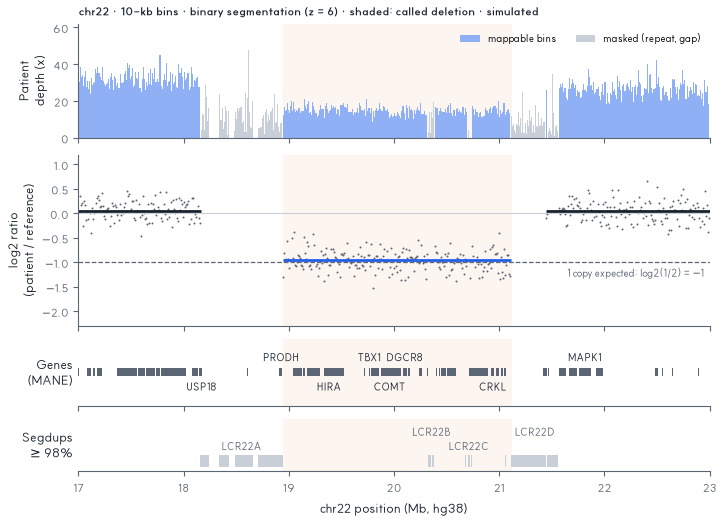

In [12]:
# Step B5.4 · four tracks on one x-axis (17-23 Mb): depth, log2 ratio + segments, genes, repeats
w = cn.loc[(cn["start"] >= 17_000_000) & (cn["end"] <= 23_000_000)]
x = (w["start"] + 5_000) / 1e6                                              # bin centres in Mb
fig, axs = plt.subplots(4, 1, figsize=(7.2, 5.2), sharex=True, layout="constrained",
                        gridspec_kw={"height_ratios": [1.2, 1.8, 0.7, 0.55]})
axs[0].fill_between(x, w["depth_patient"].where(w["mappable"]), step="mid", color=dviz.SKY, lw=0, label="mappable bins")
axs[0].fill_between(x, w["depth_patient"].where(~w["mappable"]), step="mid", color=dviz.GREY, lw=0, label="masked (repeat, gap)")
axs[0].set(ylabel="Patient\ndepth (x)", ylim=(0, 62))
axs[0].legend(loc="upper right", fontsize=7, ncol=2)
axs[1].scatter(x, w["log2"], s=2, color=dviz.SLATE, lw=0)
for _, s in seg.iterrows():
    axs[1].hlines(s["mean"], s["start"] / 1e6, s["end"] / 1e6, color=dviz.BLUE if s["copy_number"] < 1.5 else dviz.INK, lw=2)
axs[1].axhline(0, color=dviz.GREY, lw=0.8)
axs[1].axhline(-1, color=dviz.SLATE, lw=0.9, ls="--")
axs[1].text(22.95, -1.1, "1 copy expected: log2(1/2) = −1", color=dviz.SLATE, ha="right", va="top", fontsize=7)
axs[1].set(ylim=(-2.3, 1.2), ylabel="log2 ratio\n(patient / reference)", xlim=(17, 23))
draw_genes(axs[2], genes)
draw_segdups(axs[3], sd, lcr)
for ax in axs:                                                              # shade the call on every track
    ax.axvspan(d_start / 1e6, d_end / 1e6, color=dviz.HIGHLIGHT, zorder=0)
axs[3].set_xlabel("chr22 position (Mb, hg38)")
axs[0].set_title("chr22 · 10-kb bins · binary segmentation (z = 6) · shaded: called deletion · simulated", fontsize=8)
dviz.savefig(fig, "B5_tracks")
plt.show()

In [13]:
# CHECK · the key genes drawn inside the shaded region really overlap the called deletion
print("labelled genes inside the call:", ", ".join(sorted(set(KEY_GENES) & set(inside["gene"]))))
dviz.check("B5.key_genes_inside", len({"TBX1", "COMT", "HIRA", "CRKL", "DGCR8"} & set(inside["gene"])), 5)
dviz.check("B5.MAPK1_outside", "MAPK1" not in set(inside["gene"]), True)

labelled genes inside the call: COMT, CRKL, DGCR8, HIRA, TBX1
CHECK ✓ B5.key_genes_inside = 5   (reference: 5)
CHECK ✓ B5.MAPK1_outside = True   (reference: True)


True

**What changed?** Two tables (bins, segments) and two annotation files → one figure with four aligned tracks. The
shaded call (2.17 Mb) contains *TBX1*, *COMT*, *HIRA*, *CRKL* and *DGCR8*; *MAPK1* is outside;
both ends of the call sit at grey LCR22 blocks, which is where the true breakpoints are.

**Your turn.** Add `axs[0].set_xlim(19.5, 20.3)` as the last line before `dviz.savefig` and run the cell again. Why do
all four tracks zoom, although you changed only the top one? Then remove the line again.

<details><summary>Answer</summary>

`sharex=True` gives all four panels **one** x-axis object, so a new x-range on any panel applies to all of them.
In the zoom you see single 10-kb bins: *TBX1* (19.76 Mb), *COMT* (19.94 Mb)
and *DGCR8* (20.08 Mb) sit at half depth. Without `sharex=True`, each track could be zoomed
differently and a gene could *appear* inside a deletion that it is not part of.
</details>

## Step B5.5 · Visualize: the genome-wide view at 1 Mb  *(3 min)*

### Visualize

**Why this step.** A genome-wide view is how you *find* events; a zoomed track is how you *verify* them. At 1-Mb
resolution a 2-Mb constitutional deletion is only two points, while arm-level changes in a tumour are hundreds of
points. A tumour sample is a mixture: with 60% tumour cells (purity 0.6), a one-copy gain gives
log2((0.6 × 3 + 0.4 × 2) / 2) = log2(1.3) ≈ **+0.38** instead of +0.58, and a one-copy loss gives log2(0.7) ≈ **−0.51**
instead of −1.

**New terms**
* **Arm-level event** – a gain or loss of a whole chromosome arm (p = short arm, q = long arm), common in cancer.
* **Purity** – the fraction of tumour cells in a tumour sample.
* **Focal event** – a gain or loss of a small region (here about 2 Mb).

In [14]:
# Step B5.5 · genome-wide 1-Mb bins: segment every chromosome of both samples, then label each bin's state
gw = pd.read_csv(DATA / "cnv_genome_1mb.tsv", sep="\t")
gx, ticks = dviz.manhattan_x(gw["chrom"], (gw["start"] + gw["end"]) / 2, gap=1e7)
gw["x"] = gx / 1e6                                                        # cumulative position in Mb
for col in ["log2_patient", "log2_tumour"]:
    gw[col + "_seg"] = np.nan
    for chrom, rows in gw.groupby("chrom", sort=False).groups.items():
        for _, s in dviz.segment(gw.loc[rows, col], min_size=2, z=6).iterrows():
            gw.loc[rows[int(s["first"]):int(s["last"]) + 1], col + "_seg"] = s["mean"]

def state(segment_mean):
    return np.where(segment_mean > 0.15, "gain", np.where(segment_mean < -0.15, "loss", "no change"))

changed = gw.assign(state=state(gw["log2_tumour_seg"])).query("state != 'no change'")
print("tumour, 1-Mb bins in gained / lost segments:")
print(changed.groupby(["chrom", "state"], sort=False).size().to_string())

tumour, 1-Mb bins in gained / lost segments:
chrom  state
chr7   gain     160
chr8   loss      44
       gain      99
chr13  gain      96
chr17  loss      22
chr18  loss      61
chr20  gain      34


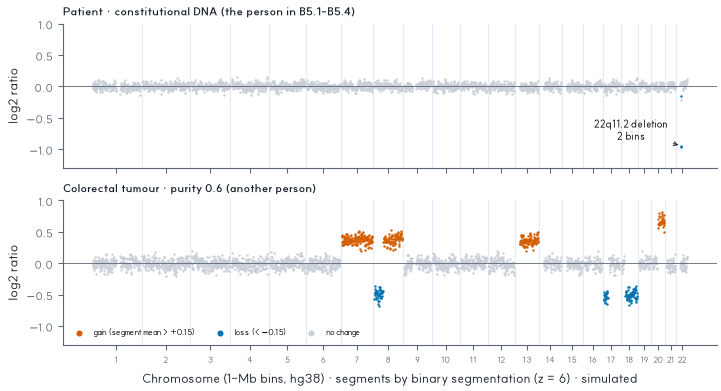

In [15]:
# Step B5.5 · two rows on one genome axis: the patient (constitutional DNA) and a tumour (purity 0.6)
COLOR = {"gain": dviz.VERMILION, "loss": dviz.OI_BLUE, "no change": dviz.GREY}
RULE = {"gain": "gain (segment mean > +0.15)", "loss": "loss (< −0.15)", "no change": "no change"}
fig, axs = plt.subplots(2, 1, figsize=(7.2, 3.9), sharex=True, sharey=True, layout="constrained")
titles = ["Patient · constitutional DNA (the person in B5.1–B5.4)", "Colorectal tumour · purity 0.6 (another person)"]
for ax, col, title in zip(axs, ["log2_patient", "log2_tumour"], titles):
    st = state(gw[col + "_seg"])
    for name, colour in COLOR.items():
        m = st == name
        ax.scatter(gw.loc[m, "x"], gw.loc[m, col], s=3, color=colour, lw=0, label=RULE[name])
    for b in gw.groupby("chrom", sort=False)["x"].min().iloc[1:] - 5:     # chromosome borders
        ax.axvline(b, color=dviz.LIGHT, lw=0.8, zorder=0)
    ax.axhline(0, color=dviz.SLATE, lw=0.6)
    ax.set(ylabel="log2 ratio", ylim=(-1.3, 1.0))
    ax.set_title(title, fontsize=8)
low22 = gw.loc[(gw["chrom"] == "chr22") & (gw["log2_patient"] < -0.5)]
axs[0].annotate(f"22q11.2 deletion\n{len(low22)} bins", xy=(low22["x"].mean(), -0.95), xytext=(low22["x"].mean() - 260, -0.85),
                fontsize=7, ha="center", arrowprops={"arrowstyle": "->", "color": dviz.INK, "lw": 0.7})
axs[1].set_xticks(ticks["centre"] / 1e6, [c.replace("chr", "") for c in ticks["chrom"]], fontsize=6)
axs[1].set_xlabel("Chromosome (1-Mb bins, hg38) · segments by binary segmentation (z = 6) · simulated")
axs[1].legend(loc="lower left", fontsize=6, ncol=3, markerscale=2.5)
dviz.savefig(fig, "B5_genome_1mb")
plt.show()

In [16]:
# Step B5.5 · helper: average 10-kb log2 ratios into bigger bins (the 1-Mb file was made this way)
def rebin(cn, size):
    """Mean log2 ratio per bin of `size` bp; needs >= 10% of its 10-kb bins to be mappable."""
    big = cn.assign(big_start=cn["start"] // size * size).groupby("big_start")["log2"].agg(["mean", "count"])
    return big["mean"].where(big["count"] >= max(1, size // 100_000))

p22 = gw.loc[gw["chrom"] == "chr22"].reset_index(drop=True)
mb22 = rebin(cn, 1_000_000).to_numpy()
print(p22.loc[16:22, ["start", "end", "log2_patient"]].assign(rebinned_from_10kb=mb22[16:23].round(4)).to_string())

       start       end  log2_patient  rebinned_from_10kb
16  16000000  17000000        0.0407              0.0407
17  17000000  18000000        0.0719              0.0719
18  18000000  19000000       -0.2118             -0.2118
19  19000000  20000000       -0.9454             -0.9454
20  20000000  21000000       -0.9733             -0.9733
21  21000000  22000000       -0.1587             -0.1587
22  22000000  23000000        0.0313              0.0313


In [17]:
# CHECK · the deletion covers only a few 1-Mb bins; the tumour gain fits purity 0.6; the 1-Mb file = our 10-kb data
n_low = int((p22["log2_patient"] < -0.5).sum())
n_overlap = int(((p22["start"] < d_end) & (p22["end"] > d_start)).sum())
print(f"chr22 1-Mb bins below -0.5: {n_low};  1-Mb bins that overlap the called deletion: {n_overlap}")
dviz.check("B5.bins_1mb_low", n_low, 2)
dviz.check("B5.bins_1mb_overlap", n_overlap, 4)
gain_8q = gw.loc[(gw["chrom"] == "chr8") & (gw["start"] >= 50_000_000), "log2_tumour"].median()
dviz.check("B5.tumour_8q_log2", gain_8q, round(float(np.log2(0.6 * 3 / 2 + 0.4)), 3), tol=0.08,
           note="expected log2(1.3) for one extra copy at purity 0.6")
same_nan = bool((np.isnan(mb22) == p22["log2_patient"].isna().to_numpy()).all())
dviz.check("B5.rebin_equals_1mb_file", same_nan and float(np.nanmax(np.abs(mb22 - p22["log2_patient"]))) < 0.001, True)

chr22 1-Mb bins below -0.5: 2;  1-Mb bins that overlap the called deletion: 4
CHECK ✓ B5.bins_1mb_low = 2   (reference: 2)
CHECK ✓ B5.bins_1mb_overlap = 4   (reference: 4)
CHECK ✓ B5.tumour_8q_log2 = 0.3821   (reference: 0.379 ± 0.08)  expected log2(1.3) for one extra copy at purity 0.6
CHECK ✓ B5.rebin_equals_1mb_file = True   (reference: True)


True

**What changed?** 10-kb bins → 1-Mb bins for the whole genome. The patient is flat except **2
bins** near −1 on 22q (19–21 Mb); 4 bins overlap the call, but the two edge bins are only
partly deleted, so they sit between 0 and −1. The tumour shows arm-level gains (7, 8q, 13, 20q) and losses (8p, 17p, 18q); the 8q
gain sits at +0.38, as predicted for one extra copy at purity 0.6 (log2 1.3 = +0.38). The chr22
rows of the 1-Mb file are exactly our 10-kb log2 ratios averaged per megabase.

**Your turn.** Before you run the next cell, predict: how many 1-Mb bins lie *completely* inside the
2.17-Mb deletion? Does the noise (SD) shrink ten-fold from 10 kb to 1 Mb, where every bin
averages 100 times more data? Run the cell, then add `50_000` and `500_000` to the list.

In [18]:
# Step B5.5 · Your turn: re-bin to bigger bins – how many lie fully inside the deletion, how noisy are they?
rows = []
for size in [10_000, 100_000, 1_000_000]:                      # try adding 50_000 and 500_000
    big = rebin(cn, size)
    starts = big.index.to_numpy()
    full = (starts >= d_start) & (starts + size <= d_end)
    far = (starts + size <= 18_000_000) | (starts >= 22_000_000)
    rows.append({"bin size (kb)": size // 1000, "bins fully inside the deletion": int(big[full].notna().sum()),
                 "SD of log2 far from 22q11.2": round(float(big[far].std()), 3)})
rebin_table = pd.DataFrame(rows)
rebin_table

,bin size (kb),bins fully inside the deletion,SD of log2 far from 22q11.2
0,10,208,0.219
1,100,21,0.075
2,1000,2,0.040


<details><summary>Answer</summary>

| bin size | bins fully inside the deletion | SD far from 22q11.2 |
|---|---|---|
| 10 kb | 208 | 0.219 |
| 100 kb | 21 | 0.075 |
| 1 Mb | 2 | 0.04 |

Only 2 bins of 1 Mb fit completely inside the deletion. The SD shrinks, but by
less than √100 = 10, because neighbouring bins share slow "waves" of coverage (correlated noise) that averaging cannot
remove. The trade-off: big bins are quiet but blur breakpoints and hide small events; small bins show breakpoints but
are noisy – so we segment small bins instead of reading single points.
</details>

## Summary

| Step | What you did | Number that proves it |
|---|---|---|
| B5.1 Question | loaded 10-kb bins of hg38 chr22 | 5,082 bins, 3,410 mappable |
| B5.2 Test | median-normalised, divided by the panel, log2, masked | outside 22q11.2 +0.049, SD 0.22; GC effect 26% → 4% |
| B5.3 Test + Check | segmented; compared with the truth | chr22:18,940,001–21,110,000, 2.17 Mb, log2 −0.96, CN 1.02; ends in LCR22A / LCR22D |
| B5.4 Visualize | four tracks on one x-axis | 42 genes in the call, incl. *TBX1*, *COMT*, *HIRA*, *CRKL*, *DGCR8* |
| B5.5 Visualize + Check | genome-wide view at 1 Mb | the deletion = 2 bins; tumour 8q +0.38 |

**Presentation sentence (fill in your numbers).**
*Question* – Does this patient carry the 22q11.2 deletion, and where are its ends?
*Takeaway* – A heterozygous deletion of 2.17 Mb of unique sequence (chr22:18,940,001–21,110,000,
hg38; mean log2 −0.96, one copy) removes 42 genes including *TBX1*; at 1 Mb it is only 2 bins.
*Limitation* – Both ends lie inside LCR22A and LCR22D, where reads cannot be placed, so read depth gives intervals of
780 and 330 kb, not exact breakpoints; the data are simulated.

In [19]:
# Step B5 · collect the numbers for the slides and the instructor: (value, unit, meaning)
gene_mb = genes.set_index("gene")["start"] / 1e6
slide = {
    "del_start_1based": (d_start + 1, "bp, hg38, 1-based", "first base of the called deletion"),
    "del_end": (d_end, "bp, hg38", "last base of the called deletion (= BED end)"),
    "del_length_Mb": (round((d_end - d_start) / 1e6, 3), "Mb", "length of the called deletion (unique sequence)"),
    "del_n_bins": (int(dele["n_bins"]), "10-kb bins", "mappable bins inside the called deletion"),
    "median_log2_inside": (round(float(median_inside), 3), "log2 ratio", "median of the bins inside the call"),
    "median_log2_outside": (round(float(cn.loc[away, "log2"].median()), 3), "log2 ratio", "median far from 22q11.2"),
    "copy_number": (round(float(dele["copy_number"]), 2), "copies", "2 x 2^(mean log2) of the deleted segment"),
    "sd_log2": (round(float(cn.loc[away, "log2"].std()), 3), "log2 ratio", "SD of single 10-kb bins, copy-neutral"),
    "se_mean_del": (round(float(cn.loc[away, "log2"].std() / np.sqrt(dele["n_bins"])), 4), "log2 ratio", "SD / sqrt(n bins)"),
    "del_minus_neutral": (round(float(dele["mean"] - cn.loc[away, "log2"].median()), 3), "log2 ratio", "deletion vs copy-neutral level"),
    "n_genes_in_call": (len(inside), "genes", "MANE Select genes overlapping the call"),
}

In [20]:
# Step B5 · more numbers: the planted truth, the uncertainty intervals and the 1-Mb view
slide.update({
    "truth_start_1based": (int(t["start"]) + 1, "bp, hg38, 1-based", "planted deletion start"),
    "truth_end": (int(t["end"]), "bp, hg38", "planted deletion end"),
    "truth_length_Mb": (round((t["end"] - t["start"]) / 1e6, 3), "Mb", "planted deletion length"),
    "start_interval_kb": (round((d_start - left) / 1e3, 1), "kb", "where the start can lie (masked LCR22A)"),
    "end_interval_kb": (round((right - d_end) / 1e3, 1), "kb", "where the end can lie (masked LCR22D)"),
    "bins_1mb_low": (n_low, "1-Mb bins", "patient chr22 bins with log2 < -0.5"),
    "bins_1mb_overlap": (n_overlap, "1-Mb bins", "1-Mb bins that overlap the call"),
    "tumour_8q_log2": (round(float(gain_8q), 3), "log2 ratio", "median of tumour 8q bins (expected log2 1.3 = 0.38)"),
    "frac_mappable_deleted": (round(int(dele["n_bins"]) / int(ok.sum()), 3), "fraction", "deleted share of mappable bins"),
    "normal_shift_pct": (round(100 * (2 ** float(cn.loc[away, "log2"].median()) - 1), 1), "%", "how much higher normal bins look"),
    "genes_planted_not_called": (", ".join(edge["gene"]), "genes", "in the planted deletion but outside the call"),
})

In [21]:
# Step B5 · add gene positions, then save everything to results/B5.json
slide.update({f"{g}_start_Mb": (round(float(gene_mb[g]), 3), "Mb, hg38", f"{g} start") for g in ["TBX1", "COMT", "DGCR8"]})
extra = {"slide_numbers": {k: {"value": a, "unit": b, "meaning": c} for k, (a, b, c) in slide.items()}}
if "rebin_table" in globals():                                       # saved too if you ran the Your-turn cell
    extra["your_turn_rebin"] = rebin_table.to_dict("records")
dviz.save_results("B5", extra=extra)
print(f"Notebook time: {time.time() - T_START:.0f} s")

saved results/B5.json  (23 values, 0 failed checks)
Notebook time: 1 s
